# Programming assignment 3 - The room, conclusion

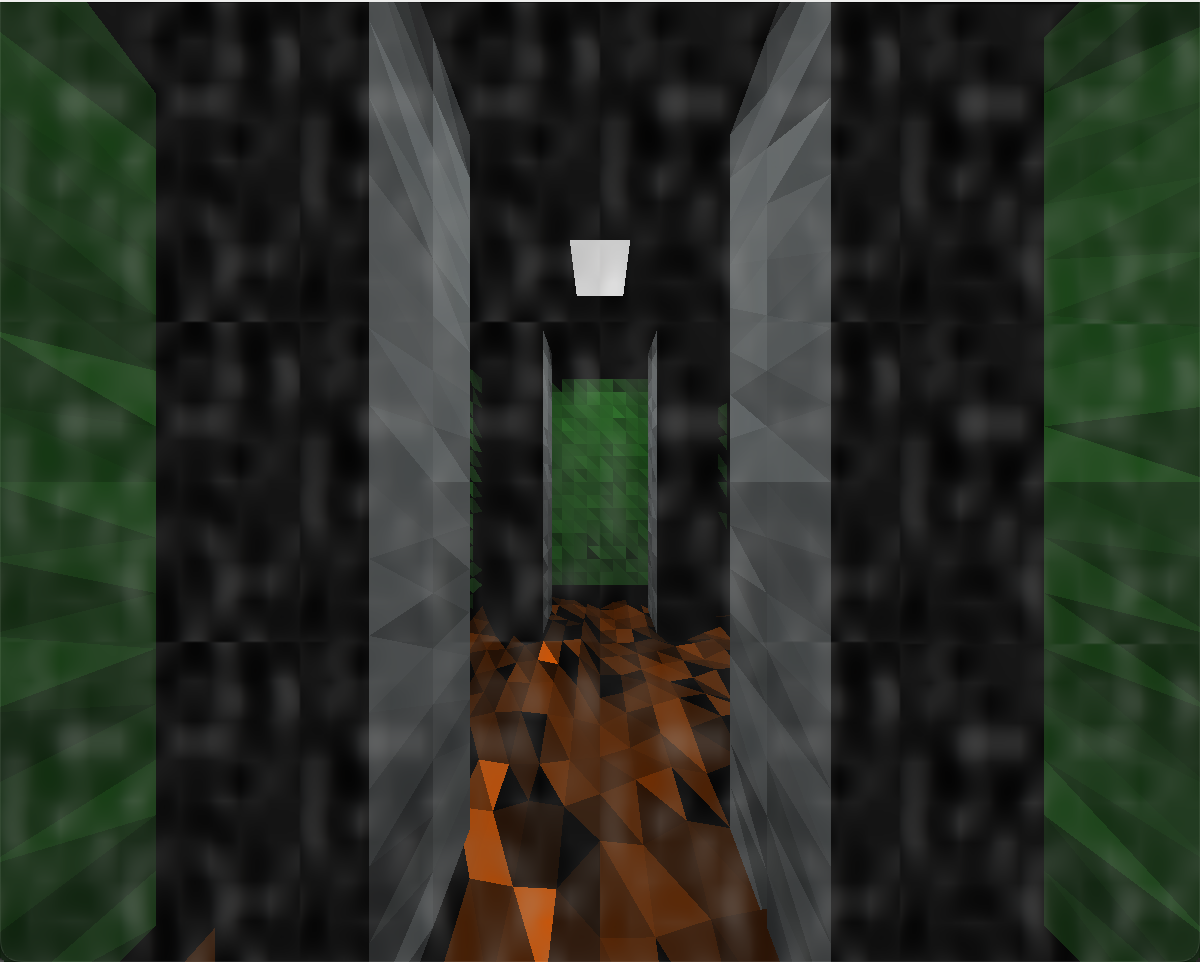

We bring to conclusion our construction of a room, by including the remaining details:

1. Obstructions, visibility and line of sight (raytracing)

2. Procedural generation of terrain (midpoint displacement)

3. Noise (Perlin noise)

The code will build on all you have done previously. You can reuse existing code, but will also obtain credit for improvements. We will grade the assignment as if it were an entirely new submission.

## 1. 3D model class [25 points]

The model class should be as in programming assignment 2 - you should build up your model from a triangular mesh, where each surface has an associated (LMS) emittivity and reflectivity.

Your class should allow you to:
1. Add nodes
2. Delete nodes
3. Add elements
4. Remove elements
5. Combine models 

When generating the model, you will want to add together separate models (as per programming assignment 2).

You may find that in the course of your program you start computing attributes of the model, for example normal vectors, etc. You may add and remove elements, rotate them, etc. For full marks you should ensure that the model does not become broken by these operations, i.e. that you don't try to reference nodes which have been removed, that you don't rotate elements whilst leaving the normal vectors unchanged.

In [ ]:
class Light_Model_3d:
    def __init__(self, nodes, elements, emit, reflect):

## 2. Generating the model [30 points]

As per assignment 2, we would like you to generate a room from scratch.

The starting point should still be code that generates (triangulated) rectangles of the desired size.

You should modify this to include an option allowing you to displace the height (or other dimension) by midpoint displacement, using your code from programming assignment 9.

If you wish, you can also add routines that generate other triangulated shapes (large triangles, hexagons etc), but you will not gain additional credit for this.

In [ ]:
@classmethod
def model_rect( # choose your arguments, you may use the same as programming assignment 2,
    # note that I have added in the option to perturb by midpoint displacement
    midpoint=False, midpoint_scale=1.0):
    
def midpoint(A,i,j,rand_scale):
    # your method can call your routine from assignment 9.

Now that you have your code, you will have to set up a room!

You can be free in your design, but there are two obligatory details:

1. At least one surface must use midpoint displacement (the floor in my example)
2. There must be at least one column (or similar obstacle) inside blocking line of sight between elements. 

The obstacle should be a 3d object (i.e. a dividing wall must be have a front and back, not simply be a flat rectangle). Try to arrange the lighting so that you can see a noticeable shadow from the object. Due to diffuse reflection and inaccuracies in the raytracing, the shadow may not be pronounced (especially if the surfaces around the room are fairly reflective), so don't worry if you don't see this effect.

## 3. The room geometry [10 points]

Having built your room, it will be useful to store certain attributes of the geometry so as to avoid computing everything several times. You may have done this already! Look at your code for surface integrals - probably you found it useful to store the areas of each element as a class attribute, perhaps the same for areas.

Your code should at a minimum store the normal vector. I ended up storing the following:

1. An orthonormal basis for each element, of which the third vector is the normal vector (i.e. a coordinate system for which the first two coordinate vectors are contained in the element, and the third coordinate vector is the normal vector) 
2. The area of each element
3. The radius of the smallest circle containing the element
4. The centroids of each element

There are no specific requirements other than the normal vector, but your code should be structured so as to avoid computing the same quantities again and again.

I used 1 and 3 of the above when ray tracing - 1 to generate rays leaving an element in the desired directions, and 3 as a heuristic to speed up checking intersections of rays with elements. 2 was mostly left in to allow for computing form factors as per programming assignment 2 and could perhaps have been omitted. 4 was used in the visibility check when drawing elements (see section 5).

## 4. The lighting [35 points]

As in programming assignment 2, you will need to: 

1. Compute the form factors between each pair of elements
2. Use the form factors to find the colour of each element

The second part remains unchanged, but we want you to use raytracing to find the form factors i.e. use your code from assignment 9. This will allow you to take into account the visibility of one surface from another.

In [ ]:
from numba import njit

@njit
def random_rays():
    # your code from assignment 9

@njit
def raytrace():
    # your code from assignment 9
    # I coded an additional routine that helps find which elements a given ray intersects
    # You don't need to structure your code like this
    
@njit
def form_factors_raytrace():
    # your code from assignment 9

Numba? Njit?

https://numba.pydata.org 

Numba is a tool to help python code run faster. This is especially useful for code involving many loops, which can be inefficient in python. My code runs perhaps 10 times as fast with numba. A few notes:

1. Class methods will not work with numba. You need to define your functions outside of the class. You can then make, e.g. $\texttt{self.form\_factors\_raytrace(n)}$ call the function $\texttt{form\_factors\_raytrace()}$ with the appropriate arguments.

2. You may need to be stricter with typing (i.e. you can't be as loose as to whether a given output is float, integer etc, that a function always outputs an argument of the same type, etc) to ensure numba works.

3. Some numpy methods are not supported. One example is the random number generator. You can use $\texttt{np.random.rand()}$, which is supported, but not $\texttt{rng.random()}$.

It is not required to use Numba, but you will likely find that it increases the quality of your output considerably. It can also ease debugging by helping code run much quicker. The form factors for the example picture at the start took a little under an hour to compute, with around 4000 elements. This could have taken up to a full day without Numba.

The Perlin noise code runs in a matter of seconds with Numba, but took over a minute without.

## 5. Drawing the room [35 points]

You should by now have obtained a list of elements with associated colours. These should be drawn to the screen in 3D perspective projection, exactly as per programming assignment 1.

There is only one caveat: we now have to deal with elements that can block the line of sight from the camera to another.

Ideally, we would also raytrace from the camera to check which elements are visible (and possibly resolve specular reflection, etc). This is really best performed at a pixel level, because the elementwise resolution will involve a complicated check of how much of element $i$ blocks element $j$, followed by a clipping procedure more complicated and time-consuming than that of programming assignment 1! **You do not need to do this!**

Nor is such a clipping really how line-of-sight issues are resolved in OpenGL and industry standard applications. You will learn more about how this is done in the graphics course you take later.

The picture at the start was drawn with a simpler algorithm: when element $i$ is to be drawn, the code checks whether a ray from the origin (the camera position) to the centroid of $i$ passes through any other elements first. If it does, the element is not drawn.

This obviously omits partially obscured elements, but for small enough elements in a dimly lit room (such as above) this is barely noticable.

Otherwise, if no visibility check is implemented, the picture will likely look good from certain viewing angles, but not others. For full points, you should implement the 'simple' algorithm above, but include an option to turn it off, as below.

In [ ]:
def draw_element(self, i, focal_length, X, Y, vis_check = True):
    # your code
    
def draw(self, focal_length, window_width, window_height, vis_check = True):
    # your code

## 6. Noise [30 points]

Perlin noise was added to the picture to help it look more organic.

Compare with the picture below (not quite the same room, run with somewhat different parameters, including a more reflective floor with higher scale parameter for the midpoint displacement. The room is a bit lighter, and the floor looks like it's trying to take over!)

Judge for yourself. I think the Perlin noise helps smooth over the abrupt transition to shadow beside the columns, and overall makes the picture seem a little more moody and less artificial.

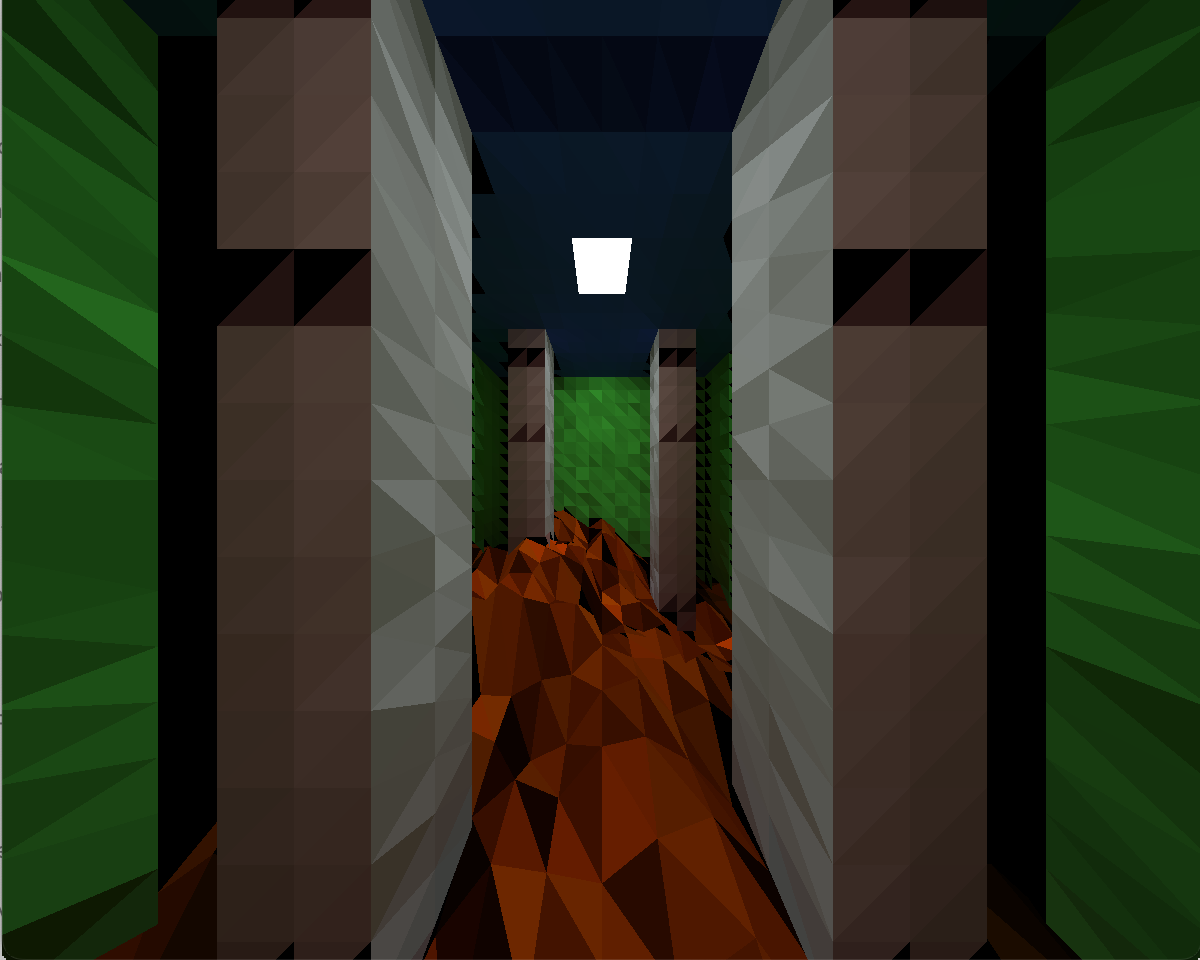

You should include an implementation of Perlin noise to obtain a similar effect (experiment and find what you think looks best).

Note that it isn't as easy to get pyglet to display pixel data as it is with numpy/matplotlib. Have a look at the code below for inspiration.

I implemented one version of the noise, which stays the same for all time.

If you want to make things even better, you can generate two separate noises, $Z_1$ and $Z_2$, and interpolate them with

$$
Z_t = t Z_1 + (1-t) Z_2,
$$

so the noise changes as time progresses! This is not required for full marks (it is a bit annoying to get this to work with pyglet sprites) but could be fun!

In [ ]:
from pyglet.gl import GLubyte

# import your code from assignment 9
# ideally use Numba here
# depending on your output you might want to rescale this
# if, for example, your noise was intended to take values between $0$ and $1$.
# Here you will want the values to be between $0$ and $255$.
Z = perlin.perlin_noise(width, height)

# generate an alpha channel, i.e. a transparency
# you can play around with the value
A = 50*np.ones((width,height))

# this makes the noise greyscale (sets RGB to be the same) and adds the alpha channel
Z = np.dstack([Z,Z,Z,A]).astype(np.uint32)

# you may need to take Z.T here, depending on how you ordered the output
# Z = Z.T

Z = Z.reshape(height*width*4)

# convert the bitmap to a form pyglet can read
Zn_data = (GLubyte * Z.size)(*Z.astype('uint8') )

# create an image of the noise
Noise = pyglet.image.ImageData(width,height,'RGBA', Zn_data, pitch=width*3)

# set the noise into a sprite for displaying in the pyglet application
sprite = pyglet.sprite.Sprite(img=Noise)

## 7. Moving about [25 points]

Having drawn the picture, you should be able to rotate and translate the model. For the most part, you can simply reuse your code from programming assignment 1.

As before, we insist that you use your own implementation of rotation with quaternions, not an external library or implementation based on matrices, Euler angles, etc.

There is only one thing to watch out for: when raytracing to check visibility, you may find yourself using, e.g. the normal vectors of an element. Your code will fail if you don't update the normal vectors on rotation. So make sure that you do this, and any other relevant geometric variables which are needed to draw the triangles with a visibility check.

## 8. The application [10 points]

To conclude, you need to write the pyglet application which loads the model, and allows the user to move about (by rotation/translation) on keyboard/mouse input.

You don't need to change anything from previous submissions.